In [ ]:
!pip install transformers datasets scikit-learn pandas


In [ ]:
from huggingface_hub import login
login()

In [ ]:
import pandas as pd

def parse_conll(path):
    rows, tokens, uid, label = [], [], None, None
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if line.startswith("meta"):
                p = line.split()
                uid, label = p[1], (p[2] if len(p) > 2 else None)
                tokens = []
            elif line.strip() == "":
                if tokens:
                    rows.append({"id": uid, "text": " ".join(tokens), "label": label})
                    tokens = []
            else:
                tokens.append(line.rsplit(None, 1)[0])
    if tokens:
        rows.append({"id": uid, "text": " ".join(tokens), "label": label})
    return pd.DataFrame(rows)

train = parse_conll("train_14k_split_conll.txt")
dev = parse_conll("dev_3k_split_conll.txt")
print(train.shape, dev.shape)
print(train["label"].value_counts())
print(train["text"].str.split().str.len().describe())
print(train.sample(5, random_state=1))

(14000, 3) (3000, 3)
label
neutral     5263
positive    4634
negative    4101
Name: count, dtype: int64
count    14000.000000
mean        26.109714
std          6.355840
min          1.000000
25%         22.000000
50%         28.000000
75%         31.000000
max         56.000000
Name: text, dtype: float64
          id                                               text     label
12339  32743  @_ Mansoor _ Ali Msg pay he to tera aur teri f...  negative
10123  27351  @ DrMuradPTI bundel of thanks Sir 👏❤❤ Allah Pa...  positive
13977  12795  @ Selvan33804547 @ Alpha _ crusader _ @ TVijay...  negative
1520   25997  @ RoflIndian3 @ sardanarohit Tum chamche nahi ...  negative
5815   41597  @ Ravikan03251268 @ narendramodi Aaj wo log Ka...  negative


In [ ]:
print(dev["label"].isna().sum())  # should print 0

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train = vec.fit_transform(train["text"])
X_dev = vec.transform(dev["text"])

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, train["label"])
pred = clf.predict(X_dev)

print("Macro F1:", f1_score(dev["label"], pred, average="macro"))
print(classification_report(dev["label"], pred))

1


TypeError: '<' not supported between instances of 'NoneType' and 'str'

In [ ]:
print("Missing labels -> train:", train["label"].isna().sum(), "| dev:", dev["label"].isna().sum())
print(train[train["label"].isna()])
print(dev[dev["label"].isna()])

train = train.dropna(subset=["label"]).reset_index(drop=True)
dev = dev.dropna(subset=["label"]).reset_index(drop=True)
print(train.shape, dev.shape)

Missing labels -> train: 2 | dev: 1
       id                                               text label
1289  Eng  Lakin is crack down ka koyi faida nahi hota .…...  None
2276  Eng  with Modiji Yogiji bound to harvest support fr...  None
      id                                     text label
920  Eng  I didn ’ t make duaa for it sksksksksks  None
(13998, 3) (2999, 3)


In [ ]:
def parse_conll(path):
    rows, tokens, uid, label = [], [], None, None
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            p = line.split()
            if len(p) == 3 and p[0] == "meta" and p[1].isdigit():
                uid, label = p[1], p[2]
                tokens = []
            elif line.strip() == "":
                if tokens:
                    rows.append({"id": uid, "text": " ".join(tokens), "label": label})
                    tokens = []
            else:
                tokens.append(line.rsplit(None, 1)[0])
    if tokens:
        rows.append({"id": uid, "text": " ".join(tokens), "label": label})
    return pd.DataFrame(rows)

train = parse_conll("train_14k_split_conll.txt")
dev = parse_conll("dev_3k_split_conll.txt")
print(train.shape, dev.shape)
print("Missing labels -> train:", train["label"].isna().sum(), "| dev:", dev["label"].isna().sum())
print(train["label"].value_counts())

(14000, 3) (3000, 3)
Missing labels -> train: 0 | dev: 0
label
neutral     5264
positive    4634
negative    4102
Name: count, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train = vec.fit_transform(train["text"])
X_dev = vec.transform(dev["text"])

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, train["label"])
pred = clf.predict(X_dev)

print("Macro F1:", f1_score(dev["label"], pred, average="macro"))
print(classification_report(dev["label"], pred))

Macro F1: 0.6115939209169489
              precision    recall  f1-score   support

    negative       0.62      0.67      0.64       890
     neutral       0.54      0.51      0.52      1128
    positive       0.67      0.67      0.67       982

    accuracy                           0.61      3000
   macro avg       0.61      0.61      0.61      3000
weighted avg       0.61      0.61      0.61      3000



In [ ]:
import numpy as np
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)
from sklearn.metrics import f1_score

label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {v: k for k, v in label2id.items()}

def run(model_name, seed=42, epochs=3, lr=2e-5, max_len=128):
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name)

    def prep(df):
        ds = Dataset.from_dict({"text": df["text"].tolist(),
                                "label": df["label"].map(label2id).tolist()})
        return ds.map(lambda b: tok(b["text"], truncation=True, max_length=max_len), batched=True)

    tr, dv = prep(train), prep(dev)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=3, id2label=id2label, label2id=label2id)

    def metrics(p):
        preds = np.argmax(p.predictions, axis=1)
        return {"macro_f1": f1_score(p.label_ids, preds, average="macro")}

    args = TrainingArguments(
        output_dir="out", num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=32, per_device_eval_batch_size=64,
        weight_decay=0.01, eval_strategy="epoch", save_strategy="no",
        fp16=True, seed=seed, report_to="none", logging_steps=100)

    trainer = Trainer(model=model, args=args, train_dataset=tr, eval_dataset=dv,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
    trainer.train()
    return trainer.evaluate()

res = run("xlm-roberta-base", seed=42)
print(res)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/14000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

... (3 outputs left out)

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1
1,0.887277,0.865447,0.583814
2,0.815403,0.818621,0.617230
3,0.734307,0.846139,0.626391


Training Loss,Validation Loss,Epoch,Macro F1
0.734307,0.846139,3,0.626391


{'eval_loss': 0.846138596534729, 'eval_macro_f1': 0.6263913432601635}


In [ ]:
res_muril = run("google/muril-base-cased", seed=42)
print(res_muril)

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

Map:   0%|          | 0/14000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

... (5 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

model.safetensors: downloading bytes:           |  0.00B            

Training Loss,Validation Loss,Epoch,Macro F1
0.755965,0.843208,3,0.630402


{'eval_loss': 0.8432080149650574, 'eval_macro_f1': 0.6304017226437203}


In [ ]:
res_mbert = run("bert-base-multilingual-cased", seed=42)
print("mBERT:", res_mbert)

res_hing = run("l3cube-pune/hing-bert", seed=42)
print("HingBERT:", res_hing)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Map:   0%|          | 0/14000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

... (17 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: l3cube-pune/hing-bert
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1
1,0.777318,0.765884,0.649362
2,0.690918,0.767941,0.669374
3,0.569351,0.804723,0.668376


Training Loss,Validation Loss,Epoch,Macro F1
0.569351,0.804723,3,0.668376


HingBERT: {'eval_loss': 0.8047227263450623, 'eval_macro_f1': 0.668375966386975}


In [ ]:
models = ["xlm-roberta-base", "google/muril-base-cased",
          "bert-base-multilingual-cased", "l3cube-pune/hing-bert"]
results = []
for m in models:
    for s in [42, 43, 44]:
        r = run(m, seed=s)
        results.append({"model": m, "seed": s, "val_f1": r["eval_macro_f1"]})
        print("DONE:", m, s, round(r["eval_macro_f1"], 4))

df_res = pd.DataFrame(results)
print(df_res)
print(df_res.groupby("model")["val_f1"].agg(["mean", "std"]).round(4))


Map:   0%|          | 0/14000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1
1,0.887339,0.861289,0.592598
2,0.816762,0.816056,0.623409
3,0.731815,0.840880,0.629652


Training Loss,Validation Loss,Epoch,Macro F1
0.731815,0.840880,3,0.629652


... (74 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: l3cube-pune/hing-bert
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1
1,0.763018,0.776583,0.662581
2,0.672939,0.775976,0.670384
3,0.564168,0.820104,0.670685


Training Loss,Validation Loss,Epoch,Macro F1
0.564168,0.820104,3,0.670685


DONE: l3cube-pune/hing-bert 44 0.6707
                           model  seed    val_f1
0               xlm-roberta-base    42  0.629652
1               xlm-roberta-base    43  0.626099
2               xlm-roberta-base    44  0.628007
3        google/muril-base-cased    42  0.630402
4        google/muril-base-cased    43  0.629867
5        google/muril-base-cased    44  0.639549
6   bert-base-multilingual-cased    42  0.607498
7   bert-base-multilingual-cased    43  0.607675
8   bert-base-multilingual-cased    44  0.619138
9          l3cube-pune/hing-bert    42  0.668376
10         l3cube-pune/hing-bert    43  0.669729
11         l3cube-pune/hing-bert    44  0.670685
                                mean     std
model                                       
bert-base-multilingual-cased  0.6114  0.0067
google/muril-base-cased       0.6333  0.0054
l3cube-pune/hing-bert         0.6696  0.0012
xlm-roberta-base              0.6279  0.0018


In [ ]:
!pip install -q transformers datasets scikit-learn pandas
import re, numpy as np, pandas as pd
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)
from sklearn.metrics import f1_score

def parse_conll(path):
    rows, tokens, uid, label = [], [], None, None
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            p = line.split()
            if len(p) == 3 and p[0] == "meta" and p[1].isdigit():
                uid, label = p[1], p[2]; tokens = []
            elif line.strip() == "":
                if tokens:
                    rows.append({"id": uid, "text": " ".join(tokens), "label": label}); tokens = []
            else:
                tokens.append(line.rsplit(None, 1)[0])
    if tokens:
        rows.append({"id": uid, "text": " ".join(tokens), "label": label})
    return pd.DataFrame(rows)

train_raw = parse_conll("train_14k_split_conll.txt")
dev_raw = parse_conll("dev_3k_split_conll.txt")
print(train_raw.shape, dev_raw.shape)

label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {v: k for k, v in label2id.items()}

def run(model_name, train_df, dev_df, seed=42, epochs=3, lr=2e-5, max_len=128):
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name)
    def prep(df):
        ds = Dataset.from_dict({"text": df["text"].tolist(),
                                "label": df["label"].map(label2id).tolist()})
        return ds.map(lambda b: tok(b["text"], truncation=True, max_length=max_len), batched=True)
    tr, dv = prep(train_df), prep(dev_df)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=3, id2label=id2label, label2id=label2id)
    def metrics(p):
        return {"macro_f1": f1_score(p.label_ids, np.argmax(p.predictions, axis=1), average="macro")}
    args = TrainingArguments(output_dir="out", num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=32, per_device_eval_batch_size=64, weight_decay=0.01,
        eval_strategy="epoch", save_strategy="no", fp16=True, seed=seed,
        report_to="none", disable_tqdm=True, logging_steps=500)
    trainer = Trainer(model=model, args=args, train_dataset=tr, eval_dataset=dv,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
    trainer.train()
    return trainer.evaluate()

def normalize(t):
    t = re.sub(r"http\S+|www\.\S+", "", t)
    t = re.sub(r"@\s*\w+", "@user", t)
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)
    return re.sub(r"\s+", " ", t).strip().lower()

train_n = train_raw.assign(text=train_raw["text"].map(normalize))
dev_n = dev_raw.assign(text=dev_raw["text"].map(normalize))

models = ["xlm-roberta-base", "google/muril-base-cased",
          "bert-base-multilingual-cased", "l3cube-pune/hing-bert"]
results_norm = []
for m in models:
    for s in [42, 43, 44]:
        r = run(m, train_n, dev_n, seed=s)
        results_norm.append({"model": m, "seed": s, "val_f1": r["eval_macro_f1"]})
        print("DONE:", m, s, round(r["eval_macro_f1"], 4))

df_norm = pd.DataFrame(results_norm)
print(df_norm.groupby("model")["val_f1"].agg(["mean", "std"]).round(4))

(14000, 3) (3000, 3)


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/14000 [00:00<?, ? examples/s]

... (78 outputs left out)

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: l3cube-pune/hing-bert
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'eval_loss': '0.7859', 'eval_macro_f1': '0.6595', 'eval_runtime': '3.018', 'eval_samples_per_second': '994.2', 'eval_steps_per_second': '15.58', 'epoch': '1'}
{'loss': '0.7788', 'grad_norm': '5.414', 'learning_rate': '1.24e-05', 'epoch': '1.142'}
{'eval_loss': '0.7783', 'eval_macro_f1': '0.6634', 'eval_runtime': '2.97', 'eval_samples_per_second': '1010', 'eval_steps_per_second': '15.83', 'epoch': '2'}
{'loss': '0.6371', 'grad_norm': '6.586', 'learning_rate': '4.795e-06', 'epoch': '2.283'}
{'eval_loss': '0.8187', 'eval_macro_f1': '0.6665', 'eval_runtime': '2.957', 'eval_samples_per_second': '1015', 'eval_steps_per_second': '15.89', 'epoch': '3'}
{'train_runtime': '156', 'train_samples_per_second': '269.2', 'train_steps_per_second': '8.423', 'train_loss': '0.6741', 'epoch': '3'}
{'eval_loss': '0.8187', 'eval_macro_f1': '0.6665', 'eval_runtime': '2.974', 'eval_samples_per_second': '1009', 'eval_steps_per_second': '15.8', 'epoch': '3'}
DONE: l3cube-pune/hing-bert 44 0.6665
               

In [ ]:
import random
rng = random.Random(123)

def noisy_word(w):
    if len(w) < 4 or w.startswith("@") or not w.isalpha():
        return w
    op = rng.choice(["drop_vowel", "double", "swap", "vowel_swap"])
    i = rng.randrange(1, len(w) - 1)
    if op == "drop_vowel":
        idx = [j for j, c in enumerate(w) if j > 0 and c in "aeiou"]
        if idx:
            j = rng.choice(idx); return w[:j] + w[j+1:]
        return w
    if op == "double":
        return w[:i] + w[i] + w[i:]
    if op == "swap":
        return w[:i] + w[i+1] + w[i] + w[i+2:]
    m = {"a": "aa", "o": "u", "u": "o", "i": "e", "e": "i"}
    idx = [j for j, c in enumerate(w) if c in m]
    if idx:
        j = rng.choice(idx); return w[:j] + m[w[j]] + w[j+1:]
    return w

dev_noisy = dev_raw.assign(text=dev_raw["text"].map(
    lambda t: " ".join(noisy_word(w) if rng.random() < 0.3 else w for w in t.split())))
print(dev_raw["text"].iloc[3]); print(dev_noisy["text"].iloc[3])

def run_robust(model_name, seed=42, epochs=3, lr=2e-5, max_len=128):
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name)
    def prep(df):
        ds = Dataset.from_dict({"text": df["text"].tolist(),
                                "label": df["label"].map(label2id).tolist()})
        return ds.map(lambda b: tok(b["text"], truncation=True, max_length=max_len), batched=True)
    tr, dv, dn = prep(train_raw), prep(dev_raw), prep(dev_noisy)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=3, id2label=id2label, label2id=label2id)
    def metrics(p):
        return {"macro_f1": f1_score(p.label_ids, np.argmax(p.predictions, axis=1), average="macro")}
    args = TrainingArguments(output_dir="out", num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=32, per_device_eval_batch_size=64, weight_decay=0.01,
        eval_strategy="no", save_strategy="no", fp16=True, seed=seed,
        report_to="none", disable_tqdm=True, logging_steps=500)
    trainer = Trainer(model=model, args=args, train_dataset=tr, eval_dataset=dv,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
    trainer.train()
    clean = trainer.evaluate(eval_dataset=dv)["eval_macro_f1"]
    noisy = trainer.evaluate(eval_dataset=dn)["eval_macro_f1"]
    return clean, noisy

rows = []
for m in models:
    for s in [42, 43, 44]:
        c, n = run_robust(m, seed=s)
        rows.append({"model": m, "seed": s, "clean": c, "noisy": n, "drop": c - n})
        print("DONE:", m, s, round(c, 4), round(n, 4))

df_rob = pd.DataFrame(rows)
print(df_rob.groupby("model")[["clean", "noisy", "drop"]].agg(["mean", "std"]).round(4))

@ DelhiPolice sir local police station pe complaint krne par bi sunwai nhi hai .. mene 5 may 2019 Ko complaint karwai … https // t . co / YUFZvNNfUz
@ DelhiPolice sir locla polici station pe complaint kren par bi sunwai nhi hai .. mine 5 may 2019 Ko complaaint karwia … https // t . co / YUFZvNNfUz


Map:   0%|          | 0/14000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (63 outputs left out)

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: l3cube-pune/hing-bert
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.7807', 'grad_norm': '5.674', 'learning_rate': '1.24e-05', 'epoch': '1.142'}
{'loss': '0.6333', 'grad_norm': '5.133', 'learning_rate': '4.795e-06', 'epoch': '2.283'}
{'train_runtime': '164.5', 'train_samples_per_second': '255.3', 'train_steps_per_second': '7.987', 'train_loss': '0.672', 'epoch': '3'}
{'eval_loss': '0.8201', 'eval_macro_f1': '0.6707', 'eval_runtime': '3.453', 'eval_samples_per_second': '868.8', 'eval_steps_per_second': '13.61', 'epoch': '3'}
{'eval_loss': '0.8665', 'eval_macro_f1': '0.651', 'eval_runtime': '3.377', 'eval_samples_per_second': '888.4', 'eval_steps_per_second': '13.92', 'epoch': '3'}
DONE: l3cube-pune/hing-bert 44 0.6707 0.651
                               clean           noisy            drop        
                                mean     std    mean     std    mean     std
model                                                                       
bert-base-multilingual-cased  0.6114  0.0067  0.5955  0.0030  0.0159  0.0074
google/muril-bas

In [2]:
!pip install -q transformers datasets scikit-learn pandas
import numpy as np, pandas as pd
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)
from sklearn.metrics import f1_score

def parse_conll(path):
    rows, tokens, uid, label = [], [], None, None
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            p = line.split()
            if len(p) == 3 and p[0] == "meta" and p[1].isdigit():
                uid, label = p[1], p[2]; tokens = []
            elif line.strip() == "":
                if tokens:
                    rows.append({"id": uid, "text": " ".join(tokens), "label": label}); tokens = []
            else:
                tokens.append(line.rsplit(None, 1)[0])
    if tokens:
        rows.append({"id": uid, "text": " ".join(tokens), "label": label})
    return pd.DataFrame(rows)

train_raw = parse_conll("train_14k_split_conll.txt")
dev_raw = parse_conll("dev_3k_split_conll.txt")
print(train_raw.shape, dev_raw.shape)

label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {v: k for k, v in label2id.items()}
models = ["xlm-roberta-base", "google/muril-base-cased",
          "bert-base-multilingual-cased", "l3cube-pune/hing-bert"]

(14000, 3) (3000, 3)


In [4]:
def fix_emoji(t):
    try:
        return t.encode("cp1252").decode("utf-8")
    except Exception:
        return t

def parse_test(path):
    rows, tokens, uid = [], [], None
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            p = line.split()
            if len(p) == 2 and p[0] == "meta" and p[1].isdigit():
                uid = p[1]; tokens = []
            elif line.strip() == "":
                if tokens:
                    rows.append({"id": uid, "text": " ".join(tokens)}); tokens = []
            else:
                tokens.append(fix_emoji(line.rsplit(None, 1)[0]))
    if tokens:
        rows.append({"id": uid, "text": " ".join(tokens)})
    return pd.DataFrame(rows)

test_x = parse_test("Hindi_test_unalbelled_conll_updated.txt")
test_y = pd.read_csv("test_labels_hinglish.txt")
test_y["id"] = test_y["Uid"].astype(str)
test_df = test_x.merge(test_y[["id", "Sentiment"]], on="id", how="left").rename(columns={"Sentiment": "label"})
print(test_df.shape, "missing labels:", test_df["label"].isna().sum())
print(test_df["label"].value_counts())
print(test_df.sample(5, random_state=1))

(3000, 3) missing labels: 0
label
neutral     1100
positive    1000
negative     900
Name: count, dtype: int64
         id                                               text     label
1957  33741  @ aamir __ 71 Aamir sir ek bharat aur world cu...  positive
2087  11579  @ iqrarulhassan Bhai main ap say zaror milna c...   neutral
1394  24689  RT @ MukeshK64587915 @ Iyervval @ vijayrupanib...  negative
1520  39942  @ sardanarohit @ br __ sharma Ashutosh Ji aap ...   neutral
1098   2783  @ ichiragpaswan Dear sir LJP ke dubara 6sit me...  positive


In [5]:
from sklearn.metrics import confusion_matrix, classification_report

def run_test(model_name, seed=42, epochs=3, lr=2e-5, max_len=128):
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name)
    def prep(df):
        ds = Dataset.from_dict({"text": df["text"].tolist(),
                                "label": df["label"].map(label2id).tolist()})
        return ds.map(lambda b: tok(b["text"], truncation=True, max_length=max_len), batched=True)
    tr, te = prep(train_raw), prep(test_df)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=3, id2label=id2label, label2id=label2id)
    args = TrainingArguments(output_dir="out", num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=32, per_device_eval_batch_size=64, weight_decay=0.01,
        eval_strategy="no", save_strategy="no", fp16=True, seed=seed,
        report_to="none", disable_tqdm=True, logging_steps=500)
    trainer = Trainer(model=model, args=args, train_dataset=tr,
                      data_collator=DataCollatorWithPadding(tok))
    trainer.train()
    out = trainer.predict(te)
    preds = np.argmax(out.predictions, axis=1)
    return f1_score(out.label_ids, preds, average="macro"), preds, out.label_ids

test_rows, best_preds = [], None
for m in models:
    for s in [42, 43, 44]:
        f1, preds, gold = run_test(m, seed=s)
        test_rows.append({"model": m, "seed": s, "test_f1": f1})
        if m == "l3cube-pune/hing-bert" and s == 42:
            best_preds = preds
        print("DONE:", m, s, round(f1, 4))

df_test = pd.DataFrame(test_rows)
print(df_test.groupby("model")["test_f1"].agg(["mean", "std"]).round(4))

names = ["negative", "neutral", "positive"]
print(confusion_matrix(gold, best_preds))
print(classification_report(gold, best_preds, target_names=names))
test_df["pred"] = [id2label[p] for p in best_preds]
test_df[test_df["pred"] != test_df["label"]].to_csv("hingbert_errors.csv", index=False)
df_test.to_csv("test_results.csv", index=False)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/14000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

... (77 outputs left out)

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: l3cube-pune/hing-bert
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.7807', 'grad_norm': '5.674', 'learning_rate': '1.24e-05', 'epoch': '1.142'}
{'loss': '0.6333', 'grad_norm': '5.133', 'learning_rate': '4.795e-06', 'epoch': '2.283'}
{'train_runtime': '160.4', 'train_samples_per_second': '261.8', 'train_steps_per_second': '8.19', 'train_loss': '0.672', 'epoch': '3'}
DONE: l3cube-pune/hing-bert 44 0.738
                                mean     std
model                                       
bert-base-multilingual-cased  0.6836  0.0023
google/muril-base-cased       0.6991  0.0008
l3cube-pune/hing-bert         0.7342  0.0051
xlm-roberta-base              0.7051  0.0051
[[695 192  13]
 [228 711 161]
 [ 28 205 767]]
              precision    recall  f1-score   support

    negative       0.73      0.77      0.75       900
     neutral       0.64      0.65      0.64      1100
    positive       0.82      0.77      0.79      1000

    accuracy                           0.72      3000
   macro avg       0.73      0.73      0.73      3000
weighted 

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
clf = LogisticRegression(max_iter=1000).fit(vec.fit_transform(train_raw["text"]), train_raw["label"])
print("TF-IDF test macro F1:", f1_score(test_df["label"], clf.predict(vec.transform(test_df["text"])), average="macro"))

err = pd.read_csv("hingbert_errors.csv")
pd.set_option("display.max_colwidth", 200)
for t, g, p in err.sample(40, random_state=1)[["text", "label", "pred"]].values:
    print(f"gold={g} pred={p} | {t}\n")


TF-IDF test macro F1: 0.6672744258272486
gold=neutral pred=negative | @ ModiLeDubega @ Pawankhera @ The _ veenaD TV nhee hota to dhong ka pta kaise lgtaa yhnx media

gold=neutral pred=negative | @ priyankagandhi In India any more . Aur ye jo tumlog nautanki laga rakhe ho Rahul Nehru wala kis ko koi farak nahi p … https // t . co / jy9L8ItRF6

gold=neutral pred=negative | Musalmaan ka durgati ka karan kisi ek party par bharosa krna congress musalmaan k liye bjp se bhi bada ghatak pa … https // t co / t4U2mc6Auw

gold=neutral pred=negative | @ mssirsa @ MamataOfficial Ram jee ko le ke bahot nautanki kar raho ! Agar sachhi man se ram jee ka naam lete to aisa … https // t . co / 0Qu2GjCxCt

gold=positive pred=neutral | @ DreamWarriorpic @ Suriya _ offl @ selvaraghavan @ thisisysr @ Sai _ Pallavi92 @ Rakulpreet @ SonyMusicSouth @ prabhu _ sr Suprb sir song is awsme

gold=neutral pred=negative | JcdPs moulladad k hudood Goth faqeerabad me 3 chor chori karty hue Gaon walon k hath pakry gaye 1

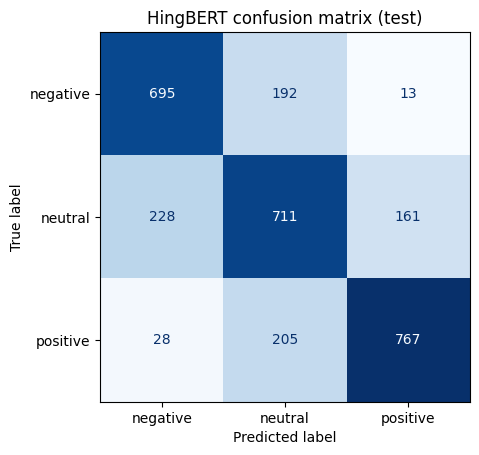

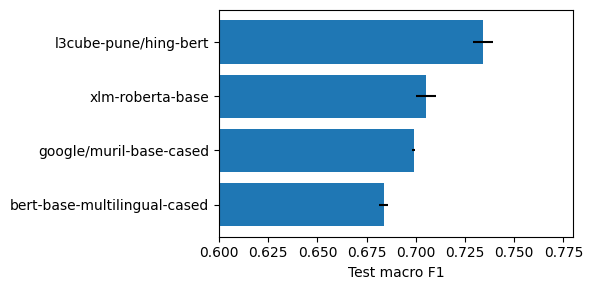

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(gold, best_preds,
    display_labels=["negative", "neutral", "positive"], cmap="Blues", colorbar=False)
plt.title("HingBERT confusion matrix (test)")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight"); plt.show()

s = df_test.groupby("model")["test_f1"].agg(["mean", "std"]).sort_values("mean")
plt.figure(figsize=(6, 3))
plt.barh(s.index, s["mean"], xerr=s["std"])
plt.xlabel("Test macro F1"); plt.xlim(0.6, 0.78); plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300); plt.show()